# NLP 文本预处理 / NLP Text Pre-processing

选择内核 **Python (ARU)**，从上到下执行。这个副本保留课堂练习，并为说明、代码注释和输出标签提供中英对照。
Choose the **Python (ARU)** kernel and run all cells in order. This copy keeps the classroom exercises and provides Chinese–English explanations, code comments and output labels.

本文件夹的 `data/nltk_data` 附带本练习需要的英文语料；首次运行不需要下载语料。复制整个作业文件夹即可保留这些资源，Python 依赖仍需按环境说明安装。
The required English resources are bundled in this folder's `data/nltk_data`; no corpus download is needed on the first run. Copy the whole assignment folder to keep these resources, and install the Python dependencies as described in the environment instructions.

## 学习目标与基本概念 / Learning goals and basic terms

理解每一步预处理做什么、为什么做，以及什么时候不适合做。练习包括空格处理、规范化、分词、词干提取、词形还原和停用词处理。
Understand what each preprocessing step does, why it is used and when it should be avoided. The exercises cover whitespace cleanup, normalization, tokenization, stemming, lemmatization and stop-word processing.

运行方式：在 JupyterLab 中选择“运行 → 运行所有单元格”。以 `#` 开头的行是注释，Python 不执行它。
To run the notebook, choose **Run → Run All Cells** in JupyterLab. A line beginning with `#` is a comment and is not executed by Python.

- **自然语言处理 / NLP:** 用计算机处理人类语言。 / Methods for working with human language using computers.
- **预处理 / Preprocessing:** 为检索、分类或分析准备数据。 / Preparing data before search, classification or analysis.
- **字符串 / String:** Python 中的文本，例如 `"Hello"`。 / Text stored in Python, such as `"Hello"`.
- **变量 / Variable:** 数据的名字，例如 `text = "Hello"` 中的 `text`。 / A name for data, such as `text` in `text = "Hello"`.
- **函数 / Function:** 可重复调用的操作，例如 `print()` 显示结果。 / A reusable operation; for example, `print()` displays a result.
- **词元 / Token:** 分词得到的单位，可能是词，也可能是标点。 / A unit produced by tokenization, such as a word or punctuation mark.
- **语料库 / Corpus:** 一组文本，例如一千条电影评论。 / A collection of texts, such as one thousand movie reviews.

预处理不是固定配方。词干提取和词形还原通常是可选择的两条分支；大模型中的标点和功能词也可能携带重要信息。
Preprocessing is not a fixed recipe. Stemming and lemmatization are often alternative branches; punctuation and function words may also carry essential meaning for language models.

## 0. 本地环境与语料 / Local environment and language resources

本练习使用 Python 内置的 `re`、`string`，以及 NLTK 和 Matplotlib。`import` 导入库；`pip` 安装 Python 包；语料文件属于数据，不是 Python 包。
This exercise uses Python's built-in `re` and `string` modules, plus NLTK and Matplotlib. `import` loads a library, `pip` installs a Python package, and corpus files are data rather than Python packages.

下面只从作业文件夹读取英文 punkt_tab、stopwords 和 WordNet，并立即检查分词、停用词和词形还原。语料来源和原许可见 `data/README.md`。
The cell below reads English punkt_tab, stopwords and WordNet only from the assignment folder and checks tokenization, stop words and lemmatization immediately. Sources and original license information are listed in `data/README.md`.

In [1]:
from pathlib import Path
import sys
import re
import string
import nltk
import matplotlib.pyplot as plt
from nltk.tokenize import word_tokenize
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.corpus import stopwords

# 同时支持从作业目录或仓库根目录运行 / Support the assignment folder and repository root.
candidates = [Path.cwd(), *Path.cwd().parents]
candidates += [p / 'assignments' / 'Week3_NLP_SPARQL' for p in candidates]
assignment_root = next((p for p in candidates
                        if (p / 'NLP_Text_Preprocessing.ipynb').is_file()
                        and (p / 'data' / 'nltk_data').is_dir()), None)
if assignment_root is None:
    raise RuntimeError('请从本作业目录或仓库根目录运行。 / Run from this assignment folder or the repository root.')

# 只用随作业提供的语料，避免依赖本机其他目录 / Use only bundled resources, without machine-specific paths.
resource_dir = assignment_root / 'data' / 'nltk_data'
nltk.data.path[:] = [str(resource_dir)]
plt.rcParams['font.sans-serif'] = ['DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
word_tokenize('Setup check.')
WordNetLemmatizer().lemmatize('running', 'v')
stopwords.words('english')
print('Python 版本 / Python version:', sys.version.split()[0])
print('语料目录 / Resource directory:', resource_dir.relative_to(assignment_root))
print('NLTK 语料检查通过，可以依次运行全部单元格。 / NLTK resource checks passed; run the remaining cells in order.')

Python 版本 / Python version: 3.12.10
语料目录 / Resource directory: data\nltk_data
NLTK 语料检查通过，可以依次运行全部单元格。 / NLTK resource checks passed; run the remaining cells in order.


## 1. 正则表达式：去掉多余空格 / Regular expressions: removing extra spaces

正则表达式是文本匹配模式，可以理解为更灵活的查找替换。`re.sub(' +', ' ', y)` 把一个或多个普通空格替换成一个空格。
A regular expression is a text-matching pattern, similar to a more flexible Find & Replace tool. `re.sub(' +', ' ', y)` replaces one or more ordinary spaces with one space.

- `re` 是模块，`sub` 是替换操作，`y` 是待处理字符串。 / `re` is the module, `sub` performs substitution, and `y` is the input string.
- `+` 表示至少重复一次；替换值 `' '` 是一个空格。 / `+` means one or more repetitions; the replacement `' '` is one space.
- `strip()` 只去掉开头和结尾的空白，不合并词间空格。 / `strip()` removes leading and trailing whitespace, without collapsing spaces between words.
- `r'\s+'` 还能处理制表符和换行；`r` 表示原始字符串，便于书写反斜杠。 / `r'\s+'` also handles tabs and line breaks; `r` marks a raw string and makes backslashes easier to write.

### 合并空格的课堂示例 / Classroom example: collapsing spaces

结合 `strip()` 和 `re.sub()`，把电影查询文本中的不均匀空格变成单个空格。`repr()` 用引号显示结果，便于观察边缘空格。
Combine `strip()` and `re.sub()` to replace uneven spacing in a movie query with single spaces. `repr()` displays quotes so that spaces at the edges are visible.

In [2]:
y = "   all movies   by David           Murphy      "
print("原文 / Original:", repr(y))  # 用引号显示空格 / Show quotes to make spaces visible.
print("1. 去首尾空白 / strip():", repr(y.strip()))
print("2. 合并空格 / re.sub():", repr(re.sub(' +', ' ', y.strip())))

# 同时处理制表符和换行 / Handle tabs and line breaks as well.
with_tabs = "  all movies\tby David\nMurphy  "
clean_spaces = re.sub(r"\s+", " ", with_tabs).strip()
print("3. 同时处理制表符和换行 / Including tabs and line breaks:", repr(clean_spaces))

原文 / Original: '   all movies   by David           Murphy      '
1. 去首尾空白 / strip(): 'all movies   by David           Murphy'
2. 合并空格 / re.sub(): 'all movies by David Murphy'
3. 同时处理制表符和换行 / Including tabs and line breaks: 'all movies by David Murphy'


## 2. 规范化：统一文本形式 / Normalization: making text consistent

规范化让形式相近的输入更容易一起处理。这里演示去标点、整理空白，以及可选的小写转换。
Normalization makes similar-looking inputs easier to process consistently. Here we demonstrate punctuation removal, whitespace cleanup and optional lowercasing.

- 标点包括 `! ? . @ ,`；`string.punctuation` 提供常见 ASCII 标点。 / Punctuation includes `! ? . @ ,`; `string.punctuation` provides common ASCII punctuation characters.
- `re.escape(...)` 让特殊符号按字面含义匹配；`[...]` 表示匹配集合内任意一个字符。 / `re.escape(...)` treats special characters literally; `[...]` matches any one character in the set.
- `text.split()` 按空白切分；`' '.join(...)` 再用一个空格拼接。 / `text.split()` splits on whitespace; `' '.join(...)` rejoins the pieces with one space.

机械去标点可能改变含义：`can't → cant`、`C++ → C`，以及移除 `@Francis` 的标记。应按任务选择。
Blind punctuation removal can change meaning: `can't → cant`, `C++ → C`, and the marker in `@Francis` disappears. Choose the operation according to the task.

### 去标点并整理空格 / Remove punctuation and clean up spacing

先用 `re.sub(f"[{re.escape(string.punctuation)}]", "", text)` 去除 ASCII 标点，再切分、重连。示例中会移除 `@` 和 `!`。
First remove ASCII punctuation with `re.sub(f"[{re.escape(string.punctuation)}]", "", text)`, then split and rejoin the text. This example removes `@` and `!`.

In [3]:
text = "all of the movies      directed by @Francis Coppola !"

# 先构造标点字符集合 / Build a punctuation character class first.
pattern = f"[{re.escape(string.punctuation)}]"
no_punctuation = re.sub(pattern, "", text)

# 按空白切分，再用单个空格连接 / Split on whitespace, then rejoin with single spaces.
processed_text = " ".join(no_punctuation.split())

print("原文 / Original:    ", text)
print("去标点 / Without punctuation:", no_punctuation)
print("规范化 / Normalized:  ", processed_text)

# 小写转换按任务选择 / Lowercasing is an optional normalization step.
print("转小写 / Lowercased:  ", processed_text.lower())

原文 / Original:     all of the movies      directed by @Francis Coppola !
去标点 / Without punctuation: all of the movies      directed by Francis Coppola 
规范化 / Normalized:   all of the movies directed by Francis Coppola
转小写 / Lowercased:   all of the movies directed by francis coppola


## 3. 分词：把句子切成词元 / Tokenization: splitting a sentence into tokens

英文分词结果通常包括单词，也可能包括标点。Python 的列表用方括号保存多个项目，例如 `["I", "learn", "NLP"]`。
English tokenization usually produces words and may also produce punctuation tokens. A Python list stores multiple items in square brackets, such as `["I", "learn", "NLP"]`.

In [4]:
# 分词后再比较词形 / Tokenize before comparing word forms.
tokens = word_tokenize(processed_text)
print("文本 / Text:  ", processed_text)
print("词元 / Tokens:", tokens)
print("词元数量 / Token count:", len(tokens))  # 统计词元数 / Count the tokens in the list.

文本 / Text:   all of the movies directed by Francis Coppola
词元 / Tokens: ['all', 'of', 'the', 'movies', 'directed', 'by', 'Francis', 'Coppola']
词元数量 / Token count: 8


## 4. 词干提取：按规则裁剪单词 / Stemming: trimming words with rules

词干提取用启发式规则移除词的一部分，通常是词尾。得到的词干不一定是词典中的真实单词。
Stemming uses heuristic rules to remove parts of a word, often its ending. The resulting stem does not have to be a real dictionary word.

- `ps = PorterStemmer()` 创建英文 Porter 词干提取器。 / `ps = PorterStemmer()` creates a Porter stemmer for English.
- `ps.stem(word)` 得到一个单词的词干。 / `ps.stem(word)` returns the stem of one word.
- `[ps.stem(x) for x in tokens]` 是列表推导式，对每个词元执行同一操作。 / `[ps.stem(x) for x in tokens]` is a list comprehension that applies the same operation to every token.

这种方法适合把不同词形归组，但不保证语言学上的精确性。
This method is useful for grouping word forms, but it does not guarantee linguistic precision.

### 词干提取示例 / Stemming example

对清理后的电影句子逐词提取词干，再用 `join()` 拼接。可能得到 `movi`、`direct`、`franci` 等形式。
Stem each word in the cleaned movie sentence, then rejoin the stems with `join()`. Forms such as `movi`, `direct` and `franci` may appear.

In [5]:
# 保留原词元，便于比较 / Keep the original tokens for comparison.
ps = PorterStemmer()
stemmed_words = [ps.stem(word) for word in tokens]
sentence_with_stemmed_words = " ".join(stemmed_words)
print("原始词元 / Original tokens:", tokens)
print("词干 / Stemmed tokens: ", stemmed_words)
print("拼接结果 / Rejoined sentence: ", sentence_with_stemmed_words)

# 逐词比较变化 / Compare the transformation of each word.
for original, changed in zip(tokens, stemmed_words):
    print(f"{original:12} → {changed}")

原始词元 / Original tokens: ['all', 'of', 'the', 'movies', 'directed', 'by', 'Francis', 'Coppola']
词干 / Stemmed tokens:  ['all', 'of', 'the', 'movi', 'direct', 'by', 'franci', 'coppola']
拼接结果 / Rejoined sentence:  all of the movi direct by franci coppola
all          → all
of           → of
the          → the
movies       → movi
directed     → direct
by           → by
Francis      → franci
Coppola      → coppola


## 5. 词形还原：寻找词典形式 / Lemmatization: finding a dictionary form

词元的基本形式称为 lemma，例如 `running → run`、`cars → car`。词形还原结合词汇信息和指定词性，而不是单纯截掉词尾。
A lemma is a dictionary form, such as `running → run` or `cars → car`. Lemmatization uses vocabulary information and the specified part of speech rather than simply trimming endings.

`WordNetLemmatizer` 使用英文 WordNet 词汇数据库。参数 `'v'` 表示动词：`lemmatizer.lemmatize(word, 'v')`。
`WordNetLemmatizer` uses the English WordNet lexical database. The argument `'v'` means verb: `lemmatizer.lemmatize(word, 'v')`.

这对 `directed → direct` 有效，但并非所有词都是动词。准确处理通常需要词性标注，区分名词、动词和形容词。
This works for `directed → direct`, but not every word is a verb. Accurate processing often requires part-of-speech tagging to distinguish nouns, verbs and adjectives.

### 按动词处理的教学示例 / Teaching example: treating every token as a verb

把所有词元都作为动词处理，会得到 `movies → movies` 和 `directed → direct`。这是 API 演示中的简化，实际项目需要根据词性选择参数。
Treating every token as a verb gives `movies → movies` and `directed → direct`. This is a simplification for demonstrating the API; real applications should choose the argument according to the word's grammatical role.

In [6]:
# 指定词性影响词形还原 / The specified part of speech affects lemmatization.
lemmatizer = WordNetLemmatizer()
lemmas_as_verbs = [lemmatizer.lemmatize(word, pos="v") for word in tokens]
print("原句 / Original sentence:", processed_text)
print("全部按动词还原 / All treated as verbs:", " ".join(lemmas_as_verbs))

print("\n为什么词性重要 / Why part of speech matters:")
for word in ["movies", "directed", "running", "better"]:
    print(f"{word:12} 名词/noun → {lemmatizer.lemmatize(word, pos='n'):10} | 动词/verb → {lemmatizer.lemmatize(word, pos='v'):10} | 形容词/adjective → {lemmatizer.lemmatize(word, pos='a')}")

原句 / Original sentence: all of the movies directed by Francis Coppola
全部按动词还原 / All treated as verbs: all of the movies direct by Francis Coppola

为什么词性重要 / Why part of speech matters:
movies       名词/noun → movie      | 动词/verb → movies     | 形容词/adjective → movies
directed     名词/noun → directed   | 动词/verb → direct     | 形容词/adjective → directed
running      名词/noun → running    | 动词/verb → run        | 形容词/adjective → running
better       名词/noun → better     | 动词/verb → better     | 形容词/adjective → good


### 直接比较词干提取与词形还原 / Compare stemming and lemmatization directly

词干提取可能产生非词典形式，例如 `studies → studi`；词形还原结合词汇和词性，可以把动词 `studies` 还原为 `study`。
Stemming may produce a nonword such as `studies → studi`; lemmatization uses vocabulary and part of speech to map the verb `studies` to `study`.

In [7]:
# 词干不必是词典单词 / A stem does not have to be a dictionary word.
examples = ["studies", "studying", "running", "movies", "directed", "better"]
print(f"{'原词 / Original':18} {'词干 / Stem':18} {'动词基本形 / Lemma (verb)':22}")
print("-" * 40)
for word in examples:
    print(f"{word:12} {ps.stem(word):12} {lemmatizer.lemmatize(word, 'v'):14}")

原词 / Original      词干 / Stem          动词基本形 / Lemma (verb)  
----------------------------------------
studies      studi        study         
studying     studi        study         
running      run          run           
movies       movi         movies        
directed     direct       direct        
better       better       better        


## 6. 停用词：决定保留哪些常见词 / Stop words: deciding which common words to keep

停用词是在一些传统检索和分类流程中被忽略的高频词，例如 `the`、`of`、`is`。
Stop words are frequent words often ignored in some traditional search and classification pipelines, such as `the`, `of` and `is`.

- `stopwords.words('english')` 读取 NLTK 英文停用词表。 / `stopwords.words('english')` loads NLTK's English stop-word list.
- `set(...)` 保存不重复的元素，便于快速判断成员关系。 / `set(...)` stores unique items and supports fast membership checks.
- `word not in stop_words` 表示保留不在停用词表中的词。 / `word not in stop_words` keeps a word if it is not in the stop-word set.

删除 `not good` 中的 `not` 会改变含义。停用词删除应按任务选择，情感分析、问答和大模型尤其需要谨慎。
Removing `not` from `not good` changes the meaning. Stop-word removal is task-dependent, especially in sentiment analysis, question answering and language models.

### 查看英文停用词表 / Inspect the English stop-word list

使用随作业提供的英文停用词数据，建立集合，并显示数量和按字母排序的前 25 个词。集合自身没有固定显示顺序。
Use the bundled English stop-word data to create a set, then display its size and the first 25 words alphabetically. A set itself has no fixed display order.

In [8]:
# 排序后显示，保证示例顺序稳定 / Sort the sample for a stable display order.
stop_words = set(stopwords.words("english"))
print("停用词数量 / Stop-word count:", len(stop_words))
print("按字母排序的示例 / Alphabetical sample:", sorted(stop_words)[:25])
print("the 是否为停用词 / Is the a stop word?", 'the' in stop_words)
print("not 是否为停用词 / Is not a stop word?", 'not' in stop_words)

no_stop_words = [word for word in tokens if word.lower() not in stop_words]
print("处理前 / Before:", tokens)
print("处理后 / After: ", no_stop_words)

停用词数量 / Stop-word count: 198
按字母排序的示例 / Alphabetical sample: ['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an', 'and', 'any', 'are', 'aren', "aren't", 'as', 'at', 'be', 'because', 'been', 'before', 'being', 'below', 'between', 'both']
the 是否为停用词 / Is the a stop word? True
not 是否为停用词 / Is not a stop word? True
处理前 / Before: ['all', 'of', 'the', 'movies', 'directed', 'by', 'Francis', 'Coppola']
处理后 / After:  ['movies', 'directed', 'Francis', 'Coppola']


## 7. 安全地调整停用词表 / Safely customizing the stop-word list

如果集合中没有 `test`，调用 `stop_words.remove("test")` 会产生 `KeyError`。常规 NLTK 英文表通常不包含这个词。
If `test` is absent, `stop_words.remove("test")` raises a `KeyError`. The standard NLTK English list does not normally include this word.

- `add('test')`：加入一个停用词。 / Add a stop word.
- `discard('test')`：存在时删除，不存在也不报错。 / Remove it if present, without an error when absent.
- `remove('the')`：删除已有元素，但元素不存在时会报错。 / Remove an existing member, raising an error if it is absent.

先复制集合再自定义，避免意外改变后续示例共享的数据。
Copy the set before customizing it to avoid unexpectedly changing data shared by later examples.

### 删除、添加与保留否定词 / Remove, add and preserve negation

课堂中的 `remove("test")` 只有在集合包含 `test` 时才有效。下面使用 `discard()`，加入项目停用词 `example`，并保留否定词 `not`。
The classroom call `remove("test")` is valid only when the set contains `test`. The cell below uses `discard()`, adds the project-specific stop word `example`, and preserves the negation word `not`.

In [9]:
custom_stop_words = set(stop_words)  # 建立独立副本 / Make an independent copy.
print("原表是否包含 test / Was test originally present?", "test" in custom_stop_words)
custom_stop_words.discard("test")  # 不存在也不报错 / No error if the item is absent.
custom_stop_words.add("example")   # 添加项目停用词 / Add a project-specific stop word.
custom_stop_words.discard("not")   # 保留否定词 / Preserve negation.
print("是否已排除 example / Is example now excluded?", "example" in custom_stop_words)
print("是否保留 not / Is not preserved as meaningful?", "not" not in custom_stop_words)

phrase = "this is not a good example"
print("原文 / Original:", phrase)
print("默认停用词处理 / Default stop-word removal: ", " ".join(w for w in phrase.split() if w not in stop_words))
print("自定义停用词处理 / Custom stop-word removal: ", " ".join(w for w in phrase.split() if w not in custom_stop_words))

原表是否包含 test / Was test originally present? False
是否已排除 example / Is example now excluded? True
是否保留 not / Is not preserved as meaningful? True
原文 / Original: this is not a good example
默认停用词处理 / Default stop-word removal:  good example
自定义停用词处理 / Custom stop-word removal:  not good


## 8. 综合处理流程 / Put the preprocessing steps together

对同一句原始文本展示不同处理结果。词干提取、词形还原和停用词过滤在这里是分支，并不要求依次叠加。
Show different processing results for the same original sentence. Stemming, lemmatization and stop-word filtering are branches here, rather than steps that must all be applied consecutively.

In [10]:
# 从同一原文生成不同分支 / Create alternative branches from the same original text.
raw = "  ALL of the movies      were DIRECTED by @Francis Coppola!  "
spacing = re.sub(r"\s+", " ", raw).strip()
normalized = re.sub(f"[{re.escape(string.punctuation)}]", "", spacing).lower()
word_list = word_tokenize(normalized)
stems = [ps.stem(w) for w in word_list]
lemmas = [lemmatizer.lemmatize(w, pos="v") for w in word_list]  # 教学简化：全部按动词处理 / Teaching simplification: treat all tokens as verbs.
filtered = [w for w in word_list if w not in custom_stop_words]

stages = {
    "原文 / Original": raw,
    "整理空白 / Whitespace cleanup": spacing,
    "规范化 / Normalized": normalized,
    "分词 / Tokenized": str(word_list),
    "词干分支 / Stemmed branch": " ".join(stems),
    "词形还原分支 / Lemmatized branch": " ".join(lemmas),
    "停用词分支 / Stop-word branch": " ".join(filtered),
}
for step, result in stages.items():
    print(f"{step:22}: {result}")

原文 / Original         :   ALL of the movies      were DIRECTED by @Francis Coppola!  
整理空白 / Whitespace cleanup: ALL of the movies were DIRECTED by @Francis Coppola!
规范化 / Normalized      : all of the movies were directed by francis coppola
分词 / Tokenized        : ['all', 'of', 'the', 'movies', 'were', 'directed', 'by', 'francis', 'coppola']
词干分支 / Stemmed branch : all of the movi were direct by franci coppola
词形还原分支 / Lemmatized branch: all of the movies be direct by francis coppola
停用词分支 / Stop-word branch: movies directed francis coppola


## 9. 可视化词元数量 / Visualize token counts

柱状图比较词元数量。普通词干提取和词形还原通常只改变词形，不改变数量；删除停用词会减少数量。图表标签使用英文，方便不同操作系统显示。
The bar chart compares token counts. Ordinary stemming and lemmatization usually change word forms without changing the count; stop-word removal reduces the count. Chart labels use English for display across operating systems.

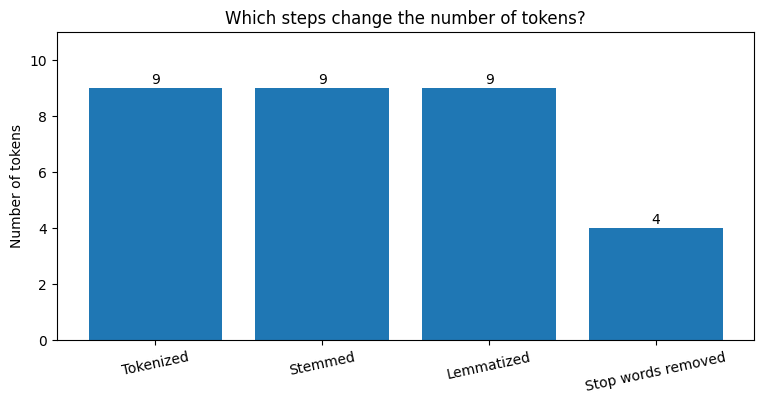

In [11]:
# 图表用英文标签，避免依赖中文字体 / Use English chart labels to avoid a CJK font dependency.
labels = ["Tokenized", "Stemmed", "Lemmatized", "Stop words removed"]
counts = [len(word_list), len(stems), len(lemmas), len(filtered)]
plt.figure(figsize=(9, 4))
rects = plt.bar(labels, counts)
plt.ylabel("Number of tokens")
plt.title("Which steps change the number of tokens?")
plt.ylim(0, max(counts) + 2)
for bar, count in zip(rects, counts):
    plt.text(bar.get_x() + bar.get_width()/2, count + 0.15, str(count), ha="center")
plt.xticks(rotation=12)
plt.show()

## 10. 小实验：换成自己的句子 / Tiny lab: try your own sentence

修改句子并重新运行，观察哪些信息消失。尤其注意否定词和标点是否影响情绪含义。
Change the sentence and rerun the cell to see which information disappears. Pay particular attention to how negation and punctuation affect sentiment.

In [12]:
# 对比删除否定词前后的含义 / Compare meaning before and after removing negation.
my_text = "I do NOT dislike these movies!!!"
my_normalized = re.sub(r"\s+", " ", my_text).strip().lower()
my_tokens = word_tokenize(my_normalized)
print("原文 / Original: ", my_text)
print("规范化 / Normalized: ", my_normalized)
print("词元 / Tokens: ", my_tokens)
print("词干 / Stems: ", [ps.stem(w) for w in my_tokens])
print("去停用词 / Stop words removed: ", [w for w in my_tokens if w not in stop_words])
print("思考：删除 not 或 do 是否改变语气？ / Think: did removing not or do change the sentiment?")

原文 / Original:  I do NOT dislike these movies!!!
规范化 / Normalized:  i do not dislike these movies!!!
词元 / Tokens:  ['i', 'do', 'not', 'dislike', 'these', 'movies', '!', '!', '!']
词干 / Stems:  ['i', 'do', 'not', 'dislik', 'these', 'movi', '!', '!', '!']
去停用词 / Stop words removed:  ['dislike', 'movies', '!', '!', '!']
思考：删除 not 或 do 是否改变语气？ / Think: did removing not or do change the sentiment?


## 11. 知识自测 / Quick knowledge check

1. `strip()` 去掉什么？会合并词间空格吗？ / What does `strip()` remove? Does it collapse spaces between words?
2. `' +'` 中的 `+` 是什么意思？ / What does `+` mean in `' +'`?
3. 为什么 `studi` 可以作为词干，却不是普通单词？ / Why can `studi` be a useful stem even though it is not an ordinary word?
4. 为什么 `'v'` 不适合所有名词？ / Why is `'v'` not appropriate for every noun?
5. 删除电影评论中的 `not` 有什么风险？ / What is the risk of removing `not` from a movie review?
6. 为什么删除可选元素时 `discard()` 更安全？ / Why is `discard()` safer when removing an optional item?

### 参考答案 / Suggested answers

1. 只去掉首尾空白，不合并词间空格。 / It removes leading and trailing whitespace, without collapsing spaces between words.
2. 重复一次或多次。 / One or more repetitions.
3. 词干不必是词典单词。 / Stems do not have to be dictionary words.
4. `'v'` 强制按动词处理。 / `'v'` forces verb treatment.
5. 可能反转原句的情绪含义。 / It may reverse the sentence's sentiment.
6. 元素不存在时不会报错。 / It does not raise an error when the item is absent.

### 在现代 NLP 中如何选择 / Choosing steps in modern NLP

传统词袋模型可能受益于规范化和停用词过滤；Transformer 和大模型通常使用自己的分词器，标点和功能词可能需要保留。英文 Porter、英文停用词和 WordNet 规则不应直接套用到中文、印地语或混合语言。
Traditional bag-of-words models may benefit from normalization and stop-word filtering. Transformers and language models usually use their own tokenizers and may need punctuation and function words. English Porter stemming, English stop words and WordNet rules should not be applied indiscriminately to Chinese, Hindi or mixed-language text.

预处理的目标是保留任务需要的信息。 / Preprocessing aims to preserve the information the task needs.

## 运行自检 / Execution self-check

核对空格处理、词干、不同词性的词形还原、否定词保留和词元数量，并确认使用作业文件夹内的语料。
Check whitespace cleanup, stems, lemmatization with different parts of speech, preserved negation and token counts, and confirm that corpus lookup uses the assignment folder.

In [13]:
# 这些断言验证关键课堂行为 / These assertions verify the key classroom behaviours.
assert re.sub(r"\s+", " ", "  AI\t is\n fun  ").strip() == "AI is fun"
assert ps.stem("studies") == "studi"
assert lemmatizer.lemmatize("running", "v") == "run"
assert lemmatizer.lemmatize("movies", "n") == "movie"
assert "not" not in custom_stop_words
assert len(stems) == len(word_list) == len(lemmas)
print("全部自检通过。 / All preprocessing self-checks passed.")
assert nltk.data.path == [str(resource_dir)]

全部自检通过。 / All preprocessing self-checks passed.
